In [68]:
import tensorflow as tf#libary deep ki diagram ke sath value dekhne ke liye (matplot)
import matplotlib.pyplot as plt

In [69]:
# dataset load
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print(x_train.shape)  # training data kitna hai
print(x_test.shape)   # test data kitna hai


(60000, 28, 28)
(10000, 28, 28)


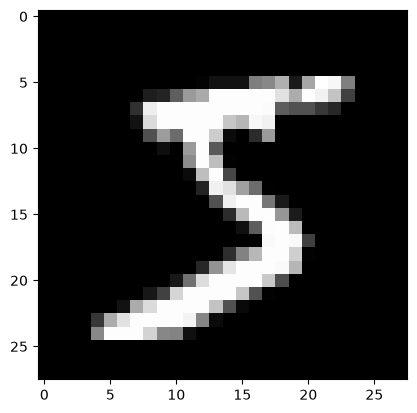

5


In [70]:
# pehli image dekho
plt.imshow(x_train[0], cmap="gray")
plt.show()
print(y_train[0])  # uska label

In [71]:
# sirf images ko 0-1 karo (labels ko NAHI)
x_train = x_train / 255.0
x_test = x_test / 255.0

In [72]:

model = tf.keras.Sequential()# 5. Model banana
# Flatten: 28x28 ki 2D image ko 784 ki 1D line mein badalta hai
model.add(tf.keras.layers.Flatten(input_shape=(28, 28)))
# Hidden layer: 128 neurons, relu activation (negative value ko 0 kar deta hai)
model.add(tf.keras.layers.Dense(128, activation="relu"))
# Output layer: 10 neurons (digit 0 se 9), softmax har digit ki probability deta hai
model.add(tf.keras.layers.Dense(10, activation="softmax"))



In [73]:
 #6. Compile (model ko seekhne ka tarika batana) ---------
model.compile(
    optimizer="adam",# weights ko behtar karne wala algorithm
    loss="sparse_categorical_crossentropy",  # galti naapne ka tarika (integer labels ke liye)
    metrics=["accuracy"] # accuracy dikhao
)

In [74]:
#model 5 baar train hoga
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32, # ek baar mein 32 images process hongi
    validation_split=0.1 # 10% data check karne ke liye alag rakho
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9208 - loss: 0.2756 - val_accuracy: 0.9657 - val_loss: 0.1288
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9646 - loss: 0.1208 - val_accuracy: 0.9732 - val_loss: 0.0987
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9765 - loss: 0.0815 - val_accuracy: 0.9747 - val_loss: 0.0899
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9834 - loss: 0.0591 - val_accuracy: 0.9760 - val_loss: 0.0873
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9879 - loss: 0.0441 - val_accuracy: 0.9750 - val_loss: 0.0867


In [75]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9740 - loss: 0.0807
Test Accuracy: 97.39999771118164 %


Enter a digit (0-9):  6


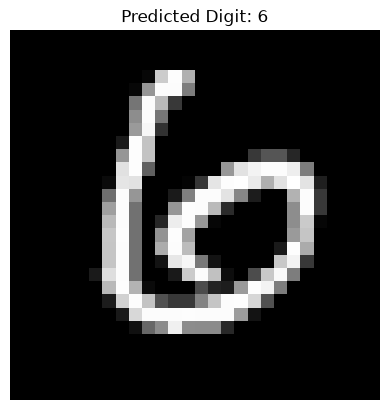

Actual Digit: 6


In [76]:
# digit se prediction
digit = int(input("Enter a digit (0-9): "))

if 0 <= digit <= 9:
    index = tf.where(y_test == digit)[0][0].numpy()
    image = x_test[index]
    prediction = model.predict(image.reshape(1, 28, 28), verbose=0)
    predicted_digit = tf.argmax(prediction[0]).numpy()

    plt.imshow(image, cmap="gray")
    plt.title(f"Predicted Digit: {predicted_digit}")
    plt.axis("off")
    plt.show()

    print("Actual Digit:", y_test[index])
else:
    print("Please enter a digit between 0 and 9.")